In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/clean_orders.csv",
                 parse_dates=["order_purchase_timestamp"])

df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M")
df["cohort_month"] = df.groupby("customer_unique_id")["order_month"].transform("min")
df["period"] = (df["order_month"] - df["cohort_month"]).apply(lambda x: x.n)

df[["customer_unique_id", "order_month", "cohort_month", "period"]].head()

C:\Users\abood\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,customer_unique_id,order_month,cohort_month,period
0,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09,1
1,af07308b275d755c9edb36a90c618231,2018-07,2018-07,0
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08,0
3,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11,0
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02,0


In [3]:
cohort_counts = (df.groupby(["cohort_month", "period"])["customer_unique_id"]
                   .nunique()
                   .unstack())

retention = cohort_counts.divide(cohort_counts[0], axis=0) * 100

# نركز على الدفعات الكبيرة فقط (أوائل 2016 صغيرة جداً)
retention = retention.loc["2017-01":"2018-03", 0:12].round(1)
retention

period,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,,
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2,0.3,0.3,0.1,0.4,0.1,0.2
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4,0.3,0.3,0.2,0.3,0.1,0.0
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4,0.1,0.3,0.3,0.3,0.3,0.2
2017-06,100.0,0.5,0.4,0.4,0.3,0.4,0.4,0.2,0.1,0.2,0.3,0.4,0.2
2017-07,100.0,0.5,0.3,0.2,0.3,0.2,0.3,0.1,0.2,0.3,0.2,0.3,0.1
2017-08,100.0,0.7,0.3,0.3,0.3,0.5,0.3,0.3,0.1,0.1,0.2,0.2,0.1
2017-09,100.0,0.7,0.5,0.3,0.4,0.2,0.2,0.2,0.3,0.2,0.2,0.1,NaN


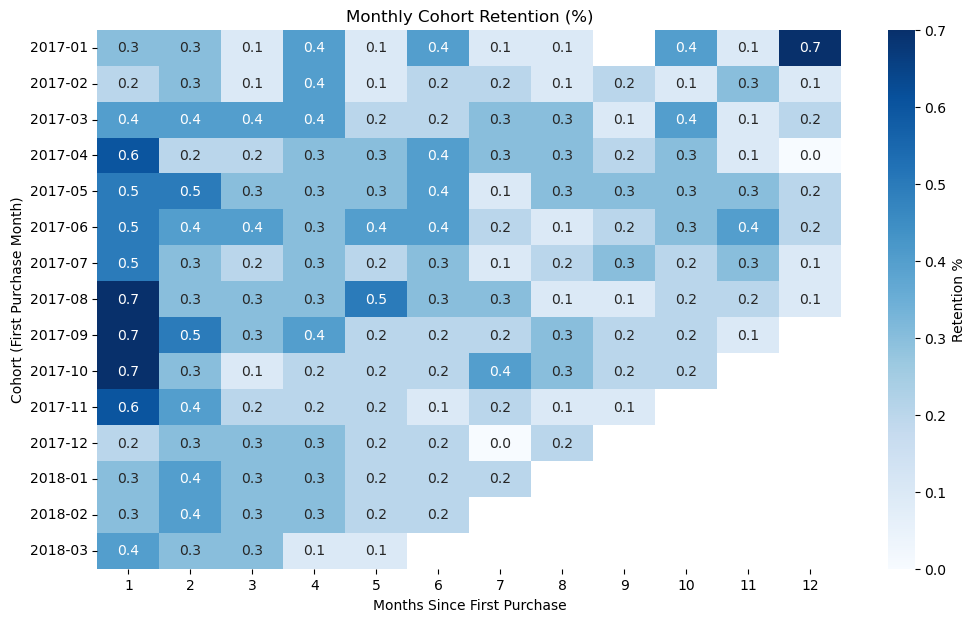

In [4]:
plt.figure(figsize=(12, 7))
sns.heatmap(retention.iloc[:, 1:], annot=True, fmt=".1f",
            cmap="Blues", cbar_kws={"label": "Retention %"})
plt.title("Monthly Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort (First Purchase Month)")
plt.savefig("../images/cohort_retention.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
retention[[1, 3, 6]].mean().round(2)

period
1    0.46
3    0.25
6    0.26
dtype: float64